# Dự đoán giá nhà Việt Nam 2024

**Dataset:** [Vietnam Housing Dataset 2024 – Kaggle](https://www.kaggle.com/datasets/nguyentiennhan/vietnam-housing-dataset-2024)

| Mục | Nội dung |
|-----|----------|
| Bài toán | Hồi quy (Regression) |
| Mục tiêu | Dự đoán giá nhà (tỉ đồng) |
| Mô hình | 5 thuật toán học máy |
| Đánh giá | MAE, MSE, RMSE, R², MAPE |
| Triển khai | Web app responsive mobile |

## 1. Import thư viện

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeRegressor

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120

print("Import thành công!")

Import thành công!


## 2. Tải dữ liệu

In [2]:
DATA_PATH = Path("/home/dau/AI/dudoangianha/DATA/vietnam_housing_dataset.csv")
MODEL_PATH = Path("/home/dau/AI/dudoangianha/best_model.pkl")

df = pd.read_csv(DATA_PATH)

print(f"Dataset: {DATA_PATH.name}")
print(f"Kích thước: {df.shape[0]:,} dòng × {df.shape[1]} cột")
df.head()

Dataset: vietnam_housing_dataset.csv
Kích thước: 30,229 dòng × 12 cột


,Address,Area,Frontage,Access Road,House direction,Balcony direction,Floors,Bedrooms,Bathrooms,Legal status,Furniture state,Price
0,"Dự án The Empire - Vinhomes Ocean Park 2, Xã L...",84.0,NaN,NaN,NaN,NaN,4.0,NaN,NaN,Have certificate,NaN,8.60
1,"Dự án The Crown - Vinhomes Ocean Park 3, Xã Ng...",60.0,NaN,NaN,NaN,NaN,5.0,NaN,NaN,NaN,NaN,7.50
2,"Dự án The Crown - Vinhomes Ocean Park 3, Xã Ng...",90.0,6.0,13.0,Đông - Bắc,Đông - Bắc,5.0,NaN,NaN,Sale contract,NaN,8.90
3,"Đường Nguyễn Văn Khối, Phường 11, Gò Vấp, Hồ C...",54.0,NaN,3.5,Tây - Nam,Tây - Nam,2.0,2.0,3.0,Have certificate,Full,5.35
4,"Đường Quang Trung, Phường 8, Gò Vấp, Hồ Chí Minh",92.0,NaN,NaN,Đông - Nam,Đông - Nam,2.0,4.0,4.0,Have certificate,Full,6.90


## 3. Khám phá dữ liệu (EDA)

In [3]:
print("=== Thông tin cột ===")
df.info()

print("\n=== Thống kê mô tả ===")
display(df.describe(include="all").T)

print("\n=== Giá trị thiếu ===")
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(1)
display(pd.DataFrame({"Thiếu": missing, "Tỉ lệ (%)": missing_pct})[missing > 0].sort_values("Tỉ lệ (%)", ascending=False))

=== Thông tin cột ===
<class 'pandas.DataFrame'>
RangeIndex: 30229 entries, 0 to 30228
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Address            30229 non-null  str    
 1   Area               30229 non-null  float64
 2   Frontage           18665 non-null  float64
 3   Access Road        16932 non-null  float64
 4   House direction    8990 non-null   str    
 5   Balcony direction  5246 non-null   str    
 6   Floors             26626 non-null  float64
 7   Bedrooms           25067 non-null  float64
 8   Bathrooms          23155 non-null  float64
 9   Legal status       25723 non-null  str    
 10  Furniture state    16110 non-null  str    
 11  Price              30229 non-null  float64
dtypes: float64(7), str(5)
memory usage: 2.8 MB

=== Thống kê mô tả ===


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Address,30229,10265,"Dự án The Empire - Vinhomes Ocean Park 2, Xã L...",187,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Area,30229.0,NaN,NaN,NaN,68.498741,48.069835,3.1,40.0,56.0,80.0,595.0
Frontage,18665.0,NaN,NaN,NaN,5.361692,4.346174,1.0,4.0,4.5,5.0,77.0
Access Road,16932.0,NaN,NaN,NaN,7.8538,7.451313,1.0,4.0,6.0,10.0,85.0
House direction,8990,8,Đông - Nam,1916,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Balcony direction,5246,8,Đông - Nam,1087,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Floors,26626.0,NaN,NaN,NaN,3.410426,1.328897,1.0,2.0,3.0,4.0,10.0
Bedrooms,25067.0,NaN,NaN,NaN,3.51103,1.309116,1.0,3.0,3.0,4.0,9.0
Bathrooms,23155.0,NaN,NaN,NaN,3.346837,1.400181,1.0,2.0,3.0,4.0,9.0
Legal status,25723,2,Have certificate,24774,NaN,NaN,NaN,NaN,NaN,NaN,NaN



=== Giá trị thiếu ===


,Thiếu,Tỉ lệ (%)
Balcony direction,24983,82.6
House direction,21239,70.3
Furniture state,14119,46.7
Access Road,13297,44.0
Frontage,11564,38.3
Bathrooms,7074,23.4
Bedrooms,5162,17.1
Legal status,4506,14.9
Floors,3603,11.9


## 4. Biểu đồ phân phối

Ba biểu đồ phân phối được xây dựng cho các đặc trưng quan trọng nhất của dữ liệu.

### Biểu đồ 1 – Phân phối giá nhà (biến mục tiêu)

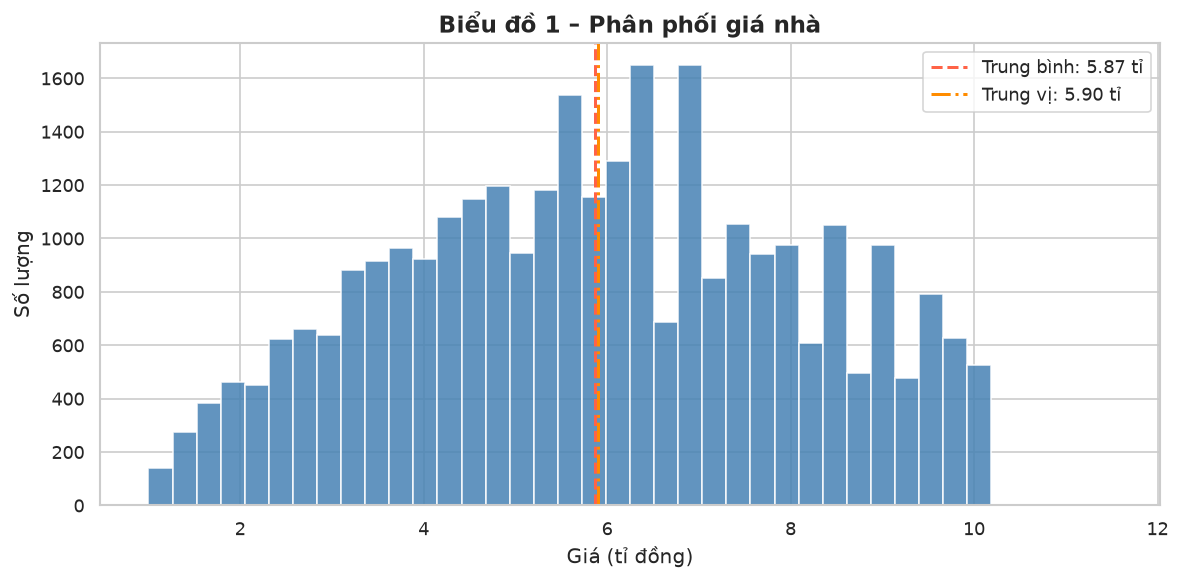

  Min: 1.0 tỉ  |  Max: 11.5 tỉ
  Trung bình: 5.8721  |  Std: 2.2119

→ Phân phối gần chuẩn, tập trung ở 4–8 tỉ đồng.


In [4]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(df["Price"], bins=40, color="steelblue", edgecolor="white", alpha=0.85)
ax.axvline(df["Price"].mean(),   color="tomato",    linestyle="--", linewidth=1.8, label=f"Trung bình: {df['Price'].mean():.2f} tỉ")
ax.axvline(df["Price"].median(), color="darkorange", linestyle="-.", linewidth=1.8, label=f"Trung vị: {df['Price'].median():.2f} tỉ")

ax.set_title("Biểu đồ 1 – Phân phối giá nhà", fontsize=14, fontweight="bold")
ax.set_xlabel("Giá (tỉ đồng)")
ax.set_ylabel("Số lượng")
ax.legend()
plt.tight_layout()
plt.show()

print(f"  Min: {df['Price'].min():.1f} tỉ  |  Max: {df['Price'].max():.1f} tỉ")
print(f"  Trung bình: {df['Price'].mean():.4f}  |  Std: {df['Price'].std():.4f}")
print("\n→ Phân phối gần chuẩn, tập trung ở 4–8 tỉ đồng.")

### Biểu đồ 2 – Phân phối diện tích (m²)

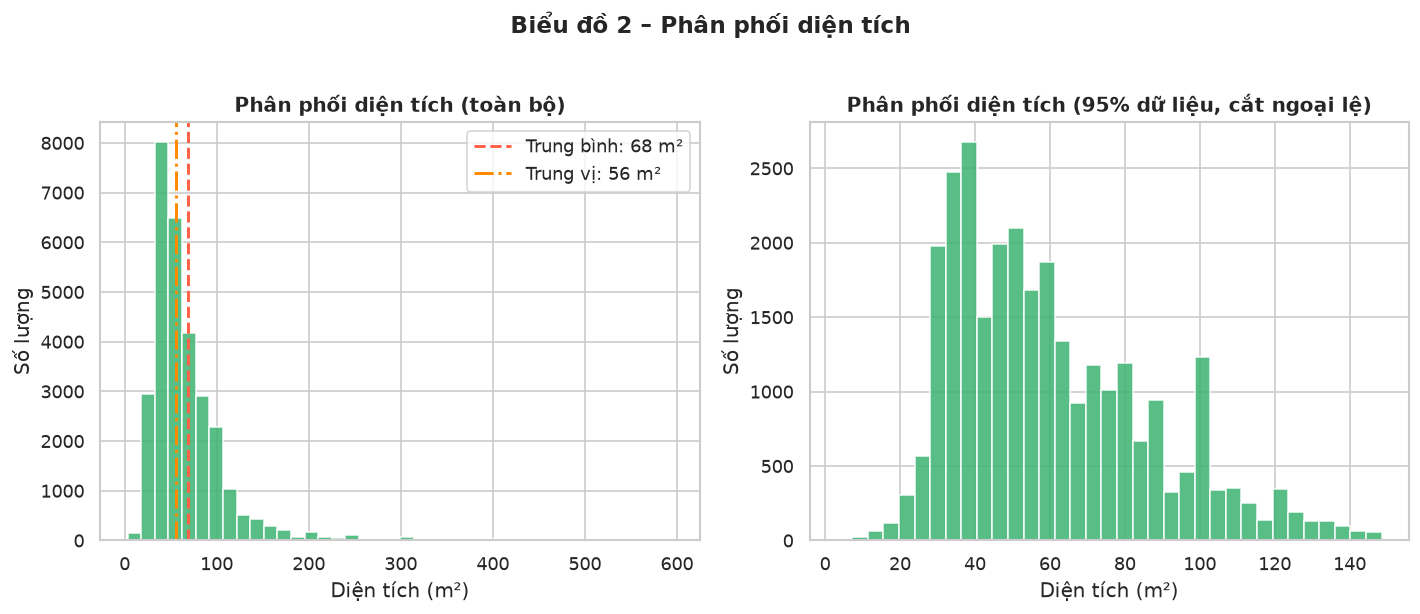

  Min: 3 m²  |  Max: 595 m²
  Trung bình: 68.5 m²  |  Trung vị: 56 m²

→ Lệch phải mạnh — phần lớn bất động sản có diện tích 30–100 m².


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Toàn bộ phân phối
axes[0].hist(df["Area"], bins=40, color="mediumseagreen", edgecolor="white", alpha=0.85)
axes[0].axvline(df["Area"].mean(),   color="tomato",    linestyle="--", linewidth=1.8, label=f"Trung bình: {df['Area'].mean():.0f} m²")
axes[0].axvline(df["Area"].median(), color="darkorange", linestyle="-.", linewidth=1.8, label=f"Trung vị: {df['Area'].median():.0f} m²")
axes[0].set_title("Phân phối diện tích (toàn bộ)", fontweight="bold")
axes[0].set_xlabel("Diện tích (m²)")
axes[0].set_ylabel("Số lượng")
axes[0].legend()

# Zoom vào 95% dữ liệu (cắt bớt ngoại lệ)
area_95 = df["Area"][df["Area"] <= df["Area"].quantile(0.95)]
axes[1].hist(area_95, bins=35, color="mediumseagreen", edgecolor="white", alpha=0.85)
axes[1].set_title("Phân phối diện tích (95% dữ liệu, cắt ngoại lệ)", fontweight="bold")
axes[1].set_xlabel("Diện tích (m²)")
axes[1].set_ylabel("Số lượng")

fig.suptitle("Biểu đồ 2 – Phân phối diện tích", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

print(f"  Min: {df['Area'].min():.0f} m²  |  Max: {df['Area'].max():.0f} m²")
print(f"  Trung bình: {df['Area'].mean():.1f} m²  |  Trung vị: {df['Area'].median():.0f} m²")
print("\n→ Lệch phải mạnh — phần lớn bất động sản có diện tích 30–100 m².")

### Biểu đồ 3 – Phân phối số phòng ngủ & phòng tắm

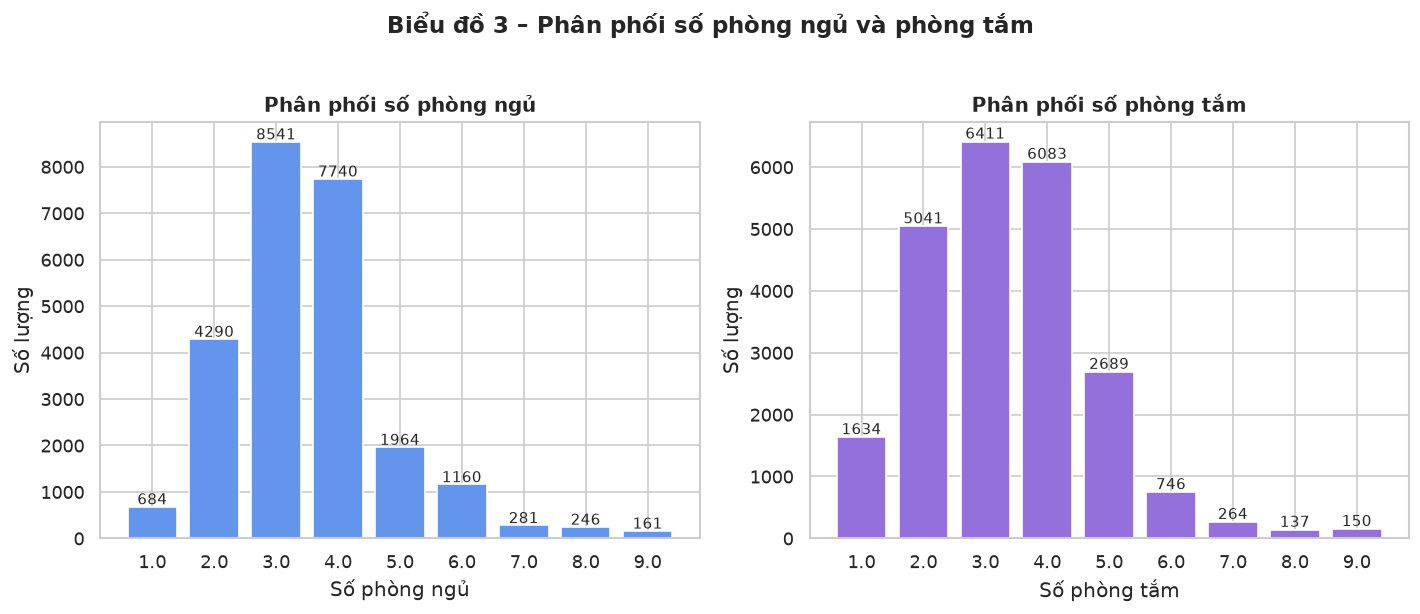

  Phòng ngủ — Trung vị: 3  |  Trung bình: 3.51
  Phòng tắm — Trung vị: 3  |  Trung bình: 3.35

→ Phần lớn bất động sản có 3 phòng ngủ và 2–3 phòng tắm.


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Phòng ngủ
bed_counts = df["Bedrooms"].value_counts().sort_index().dropna()
axes[0].bar(bed_counts.index.astype(str), bed_counts.values, color="cornflowerblue", edgecolor="white")
axes[0].set_title("Phân phối số phòng ngủ", fontweight="bold")
axes[0].set_xlabel("Số phòng ngủ")
axes[0].set_ylabel("Số lượng")
for i, v in enumerate(bed_counts.values):
    axes[0].text(i, v + 50, str(v), ha="center", fontsize=9)

# Phòng tắm
bath_counts = df["Bathrooms"].value_counts().sort_index().dropna()
axes[1].bar(bath_counts.index.astype(str), bath_counts.values, color="mediumpurple", edgecolor="white")
axes[1].set_title("Phân phối số phòng tắm", fontweight="bold")
axes[1].set_xlabel("Số phòng tắm")
axes[1].set_ylabel("Số lượng")
for i, v in enumerate(bath_counts.values):
    axes[1].text(i, v + 50, str(v), ha="center", fontsize=9)

fig.suptitle("Biểu đồ 3 – Phân phối số phòng ngủ và phòng tắm", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

print(f"  Phòng ngủ — Trung vị: {df['Bedrooms'].median():.0f}  |  Trung bình: {df['Bedrooms'].mean():.2f}")
print(f"  Phòng tắm — Trung vị: {df['Bathrooms'].median():.0f}  |  Trung bình: {df['Bathrooms'].mean():.2f}")
print("\n→ Phần lớn bất động sản có 3 phòng ngủ và 2–3 phòng tắm.")

## 5. Tiền xử lý dữ liệu

In [7]:
TARGET = "Price"

NUMERIC_FEATURES = [
    "Area",
    "Frontage",
    "Access Road",
    "Floors",
    "Bedrooms",
    "Bathrooms",
]

CATEGORICAL_FEATURES = [
    "House direction",
    "Balcony direction",
    "Legal status",
    "Furniture state",
]

ALL_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

X = df[ALL_FEATURES].copy()
y = df[TARGET].copy()

print(f"Features: {len(ALL_FEATURES)} cột  ({len(NUMERIC_FEATURES)} số + {len(CATEGORICAL_FEATURES)} phân loại)")
print(f"X shape: {X.shape}  |  y shape: {y.shape}")

Features: 10 cột  (6 số + 4 phân loại)
X shape: (30229, 10)  |  y shape: (30229,)


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print(f"Tập train: {X_train.shape[0]:,} mẫu")
print(f"Tập test : {X_test.shape[0]:,} mẫu")

Tập train: 24,183 mẫu
Tập test : 6,046 mẫu


In [9]:
# Pipeline tiền xử lý chung
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("onehot",  OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer,      NUMERIC_FEATURES),
    ("cat", categorical_transformer,  CATEGORICAL_FEATURES),
])

print("Preprocessor đã sẵn sàng.")

Preprocessor đã sẵn sàng.


## 6. Xây dựng 5 mô hình học máy

| # | Mô hình | Mô tả |
|---|---------|-------|
| 1 | **Linear Regression** | Hồi quy tuyến tính cơ bản |
| 2 | **Ridge Regression** | Hồi quy tuyến tính có L2 regularization |
| 3 | **Decision Tree** | Cây quyết định, max_depth=15 |
| 4 | **Random Forest** | Rừng ngẫu nhiên, 100 cây, max_depth=15 |
| 5 | **Gradient Boosting** | Boosting tuần tự, 100 estimators |

In [10]:
model_defs = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(alpha=1.0),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=15,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        max_depth=5,
        learning_rate=0.05,
        random_state=42
    ),
}

trained_models = {}

for name, regressor in model_defs.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor",    regressor)
    ])
    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline
    print(f"  ✓ {name}")

print("\nĐã huấn luyện xong 5 mô hình.")

  ✓ Linear Regression


  ✓ Ridge Regression


  ✓ Decision Tree


  ✓ Random Forest


  ✓ Gradient Boosting

Đã huấn luyện xong 5 mô hình.


## 7. Đánh giá 5 mô hình với 5 độ đo

| Độ đo | Ý nghĩa | Tốt hơn khi |
|-------|---------|-------------|
| **MAE** | Sai số tuyệt đối trung bình | Thấp hơn |
| **MSE** | Sai số bình phương trung bình | Thấp hơn |
| **RMSE** | Căn bậc hai MSE (cùng đơn vị với giá) | Thấp hơn |
| **R²** | Hệ số xác định (1 = hoàn hảo) | Cao hơn |
| **MAPE** | Sai số phần trăm tuyệt đối trung bình | Thấp hơn |

In [11]:
records = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test)

    mse  = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae  = mean_absolute_error(y_test, y_pred)
    r2   = r2_score(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100

    records.append({
        "Mô hình":   name,
        "MAE":       round(mae,  4),
        "MSE":       round(mse,  4),
        "RMSE":      round(rmse, 4),
        "R²":        round(r2,   4),
        "MAPE (%)": round(mape, 2),
    })

results_df = (
    pd.DataFrame(records)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

# Highlight hàng tốt nhất
def highlight_best(s):
    is_best = s == (s.min() if s.name != "R²" else s.max())
    return ["background-color: #d4edda; font-weight: bold" if v else "" for v in is_best]

display(
    results_df.style
    .apply(highlight_best, subset=["MAE", "MSE", "RMSE", "R²", "MAPE (%)"])
    .set_caption("Bảng so sánh 5 mô hình – 5 độ đo (màu xanh = tốt nhất)")
)

,Mô hình,MAE,MSE,RMSE,R²,MAPE (%)
0,Random Forest,1.440600,3.301400,1.817000,0.322900,32.740000
1,Gradient Boosting,1.463200,3.314000,1.820400,0.320300,33.500000
2,Ridge Regression,1.609700,3.889500,1.972200,0.202300,37.180000
3,Linear Regression,1.609700,3.889500,1.972200,0.202300,37.180000
4,Decision Tree,1.585800,4.227000,2.056000,0.133100,35.390000


### Biểu đồ so sánh RMSE và R² của 5 mô hình

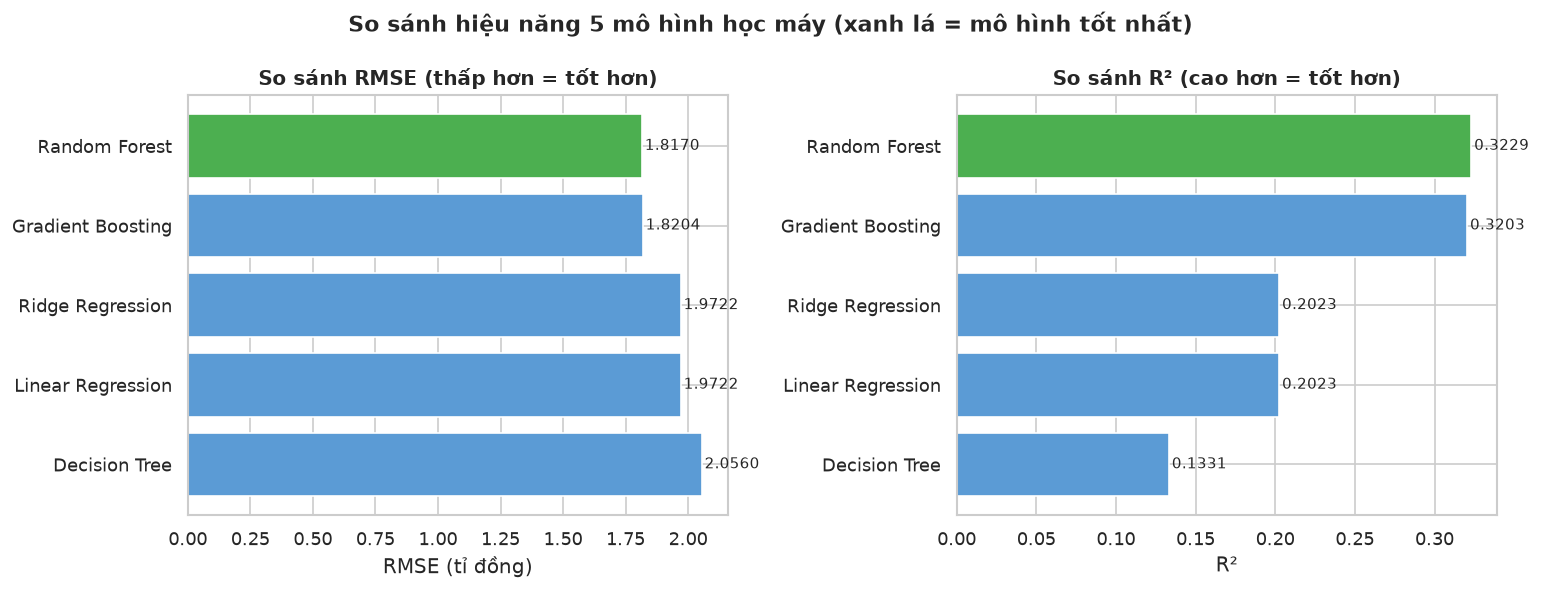

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

colors = ["#4CAF50" if i == 0 else "#5B9BD5" for i in range(len(results_df))]

# RMSE
bars1 = axes[0].barh(results_df["Mô hình"], results_df["RMSE"], color=colors, edgecolor="white")
axes[0].set_title("So sánh RMSE (thấp hơn = tốt hơn)", fontweight="bold")
axes[0].set_xlabel("RMSE (tỉ đồng)")
for bar, val in zip(bars1, results_df["RMSE"]):
    axes[0].text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
                 f"{val:.4f}", va="center", fontsize=9)
axes[0].invert_yaxis()

# R²
bars2 = axes[1].barh(results_df["Mô hình"], results_df["R²"], color=colors, edgecolor="white")
axes[1].set_title("So sánh R² (cao hơn = tốt hơn)", fontweight="bold")
axes[1].set_xlabel("R²")
for bar, val in zip(bars2, results_df["R²"]):
    axes[1].text(bar.get_width() + 0.002, bar.get_y() + bar.get_height()/2,
                 f"{val:.4f}", va="center", fontsize=9)
axes[1].invert_yaxis()

fig.suptitle("So sánh hiệu năng 5 mô hình học máy (xanh lá = mô hình tốt nhất)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

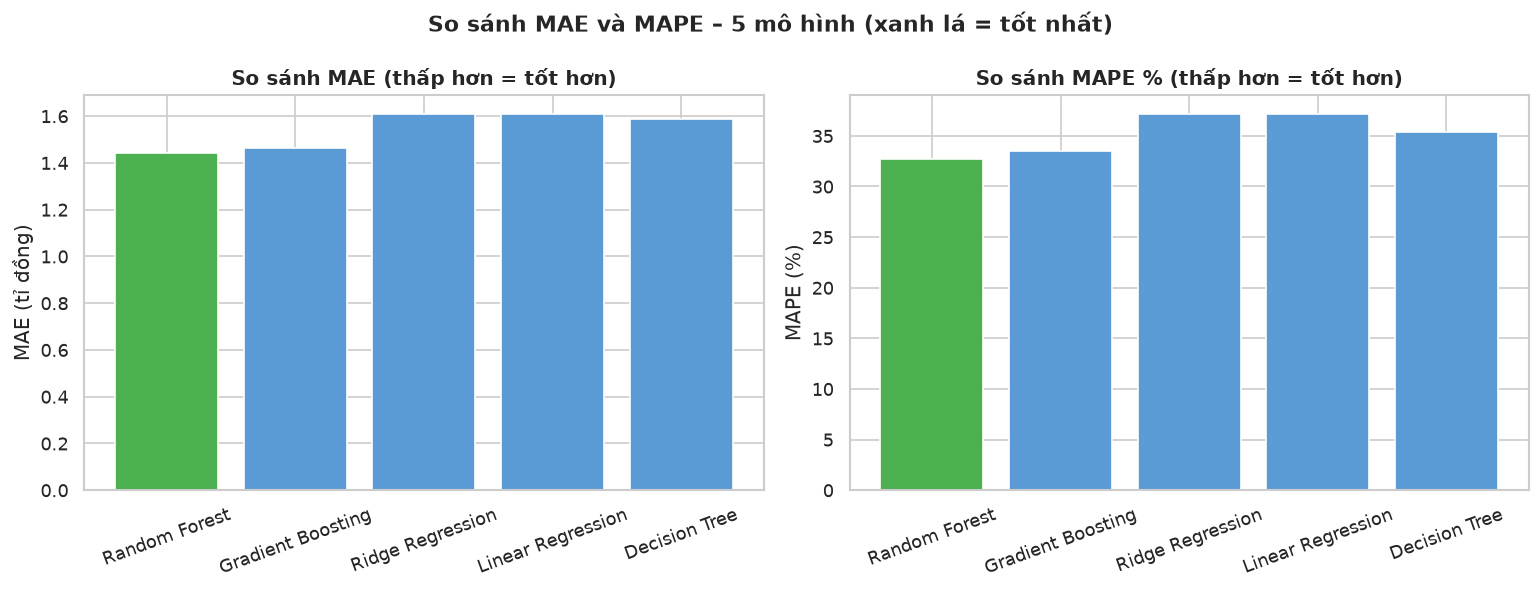

In [13]:
# Radar chart - tổng hợp 5 độ đo
metrics_for_radar = ["MAE", "MSE", "RMSE", "MAPE (%)"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# MAE
axes[0].bar(results_df["Mô hình"], results_df["MAE"],
            color=["#4CAF50" if i == 0 else "#5B9BD5" for i in range(len(results_df))],
            edgecolor="white")
axes[0].set_title("So sánh MAE (thấp hơn = tốt hơn)", fontweight="bold")
axes[0].set_ylabel("MAE (tỉ đồng)")
axes[0].tick_params(axis="x", rotation=20)

# MAPE
axes[1].bar(results_df["Mô hình"], results_df["MAPE (%)"],
            color=["#4CAF50" if i == 0 else "#5B9BD5" for i in range(len(results_df))],
            edgecolor="white")
axes[1].set_title("So sánh MAPE % (thấp hơn = tốt hơn)", fontweight="bold")
axes[1].set_ylabel("MAPE (%)")
axes[1].tick_params(axis="x", rotation=20)

fig.suptitle("So sánh MAE và MAPE – 5 mô hình (xanh lá = tốt nhất)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 8. Rút ra mô hình tốt nhất

In [14]:
best_row  = results_df.iloc[0]
best_name = best_row["Mô hình"]
best_model = trained_models[best_name]

print("=" * 50)
print(f"  MÔ HÌNH TỐT NHẤT: {best_name}")
print("=" * 50)
print(f"  MAE    : {best_row['MAE']:.4f} tỉ đồng")
print(f"  MSE    : {best_row['MSE']:.4f}")
print(f"  RMSE   : {best_row['RMSE']:.4f} tỉ đồng")
print(f"  R²     : {best_row['R²']:.4f}")
print(f"  MAPE   : {best_row['MAPE (%)']:.2f} %")
print("=" * 50)
print(f"\n→ {best_name} đạt RMSE thấp nhất và R² cao nhất trong 5 mô hình.")

  MÔ HÌNH TỐT NHẤT: Random Forest
  MAE    : 1.4406 tỉ đồng
  MSE    : 3.3014
  RMSE   : 1.8170 tỉ đồng
  R²     : 0.3229
  MAPE   : 32.74 %

→ Random Forest đạt RMSE thấp nhất và R² cao nhất trong 5 mô hình.


### Biểu đồ Actual vs Predicted – Mô hình tốt nhất

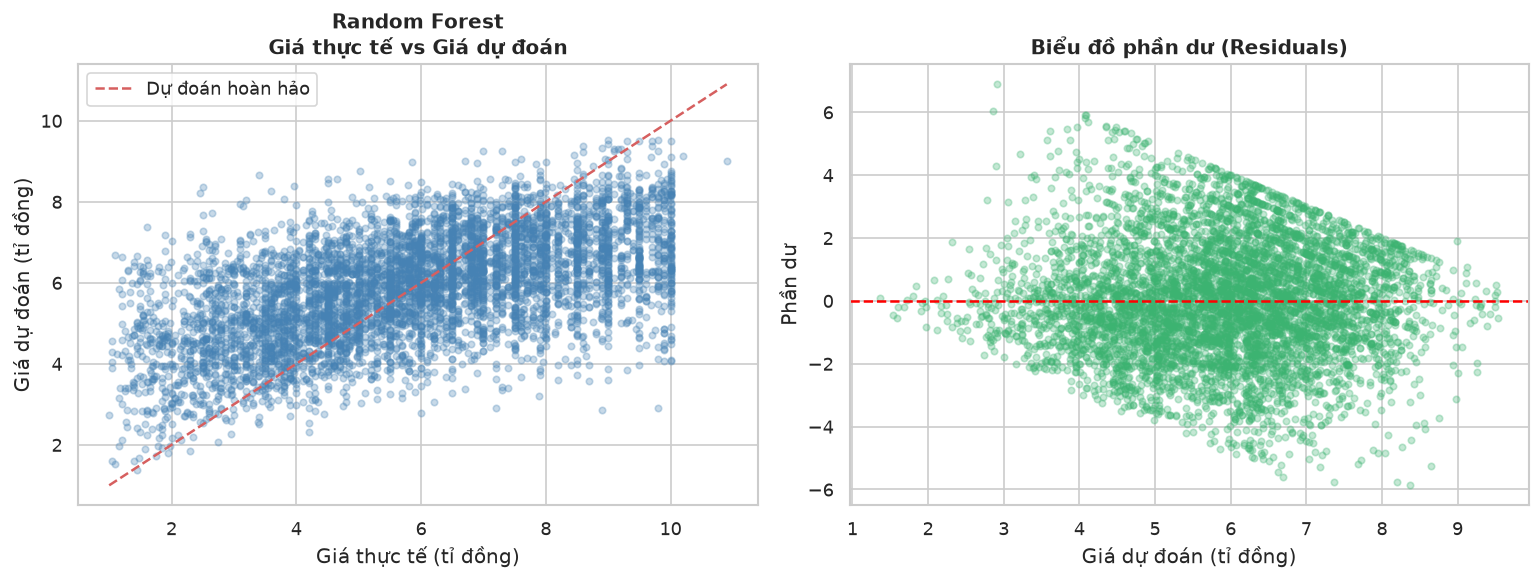

In [15]:
y_pred_best = best_model.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Scatter actual vs predicted
min_v = min(y_test.min(), y_pred_best.min())
max_v = max(y_test.max(), y_pred_best.max())

axes[0].scatter(y_test, y_pred_best, alpha=0.3, s=15, color="steelblue")
axes[0].plot([min_v, max_v], [min_v, max_v], "r--", linewidth=1.5, label="Dự đoán hoàn hảo")
axes[0].set_title(f"{best_name}\nGiá thực tế vs Giá dự đoán", fontweight="bold")
axes[0].set_xlabel("Giá thực tế (tỉ đồng)")
axes[0].set_ylabel("Giá dự đoán (tỉ đồng)")
axes[0].legend()

# Residual plot
residuals = y_test.values - y_pred_best
axes[1].scatter(y_pred_best, residuals, alpha=0.3, s=15, color="mediumseagreen")
axes[1].axhline(0, color="red", linestyle="--", linewidth=1.5)
axes[1].set_title("Biểu đồ phần dư (Residuals)", fontweight="bold")
axes[1].set_xlabel("Giá dự đoán (tỉ đồng)")
axes[1].set_ylabel("Phần dư")

plt.tight_layout()
plt.show()

## 9. Lưu mô hình tốt nhất

In [16]:
joblib.dump(best_model, MODEL_PATH)

size_mb = MODEL_PATH.stat().st_size / 1024 / 1024
print(f"Đã lưu mô hình: {MODEL_PATH}")
print(f"Kích thước file: {size_mb:.1f} MB")
print(f"Mô hình: {best_name}")

Đã lưu mô hình: /home/dau/AI/dudoangianha/best_model.pkl
Kích thước file: 50.5 MB
Mô hình: Random Forest


## 10. Triển khai – Kiểm tra dự đoán mẫu

In [17]:
# Load lại model để kiểm tra
loaded_model = joblib.load(MODEL_PATH)

test_cases = pd.DataFrame([
    {
        "Area": 60, "Frontage": 4.0, "Access Road": 5.0,
        "Floors": 3, "Bedrooms": 3, "Bathrooms": 2,
        "House direction": "Đông - Nam", "Balcony direction": "Đông",
        "Legal status": "Have certificate", "Furniture state": "Basic",
    },
    {
        "Area": 120, "Frontage": 7.0, "Access Road": 8.0,
        "Floors": 5, "Bedrooms": 5, "Bathrooms": 4,
        "House direction": "Nam", "Balcony direction": "Nam",
        "Legal status": "Have certificate", "Furniture state": "Full",
    },
    {
        "Area": 40, "Frontage": None, "Access Road": None,
        "Floors": 2, "Bedrooms": 2, "Bathrooms": 1,
        "House direction": None, "Balcony direction": None,
        "Legal status": "Sale contract", "Furniture state": None,
    },
])

predictions = loaded_model.predict(test_cases)

print("=== Kết quả dự đoán mẫu ===")
for i, pred in enumerate(predictions, 1):
    area = test_cases.iloc[i-1]["Area"]
    beds = test_cases.iloc[i-1]["Bedrooms"]
    print(f"  Nhà {i}: {area} m², {beds} phòng ngủ  →  Dự đoán: {pred:.2f} tỉ đồng")

print(f"\nWeb app đang chạy tại: http://localhost:5000")
print(f"Model được deploy: {MODEL_PATH.name}  |  {best_name}")

=== Kết quả dự đoán mẫu ===
  Nhà 1: 60 m², 3 phòng ngủ  →  Dự đoán: 4.20 tỉ đồng
  Nhà 2: 120 m², 5 phòng ngủ  →  Dự đoán: 8.27 tỉ đồng
  Nhà 3: 40 m², 2 phòng ngủ  →  Dự đoán: 1.61 tỉ đồng

Web app đang chạy tại: http://localhost:5000
Model được deploy: best_model.pkl  |  Random Forest
